[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eirasf/GCED-AA2/blob/main/es/lab9/lab9.ipynb)

# Práctica 9: RNNs

## Pre-requisitos
En esta práctica utilizaremos los paquetes `pandas` y `seaborn` para examinar y manipular los datos.

In [1]:
# Hacemos los imports que sean necesarios
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Pronóstico de series de tiempo

Vamos a utilizar un [conjunto de datos de series de tiempo meteorológicas](https://www.bgc-jena.mpg.de/wetter/) registradas por el Instituto Max Planck de Biogeoquímica.

Este conjunto de datos contiene 14 características diferentes, como la temperatura del aire, la presión atmosférica y la humedad. Estos se recopilaron cada 10 minutos, de 2009 a 2016.

Lo primero que vamos a hacer es cargar los datos en un DataFrame de la librería [Pandas](https://pandas.pydata.org/).

## Carga de los datos
En la siguiente celda descargaremos los datos y los cargaremos en un `DataFrame` de `pandas`.

In [2]:
import urllib.request

print('Downloading...')
urllib.request.urlretrieve('https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip', 'jena_climate_2009_2016.csv.zip')
print("Download complete! Unzipping...")

import zipfile
with zipfile.ZipFile("jena_climate_2009_2016.csv.zip", "r") as zip_ref:
    zip_ref.extractall("./")
print("Your data is ready!")

df = pd.read_csv('jena_climate_2009_2016.csv')[::6]

Downloading...
Download complete! Unzipping...
Your data is ready!


## Visualización de los datos

Antes de nada, vamos a echar un vistazo a los datos.

In [3]:
df.head()

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
6,01.01.2009 01:10:00,996.50,-7.62,265.81,-8.30,94.8,3.44,3.26,0.18,2.04,3.27,1305.68,0.18,0.63,166.5
12,01.01.2009 02:10:00,996.63,-8.85,264.57,-9.70,93.5,3.12,2.92,0.20,1.82,2.93,1312.11,0.16,0.50,158.3
18,01.01.2009 03:10:00,996.87,-8.84,264.56,-9.69,93.5,3.13,2.92,0.20,1.83,2.93,1312.37,0.07,0.25,129.3
24,01.01.2009 04:10:00,997.05,-9.23,264.15,-10.25,92.2,3.03,2.79,0.24,1.74,2.80,1314.62,0.10,0.38,203.9


También podemos ver como cambian los datos de las variables a lo largo del tiempo

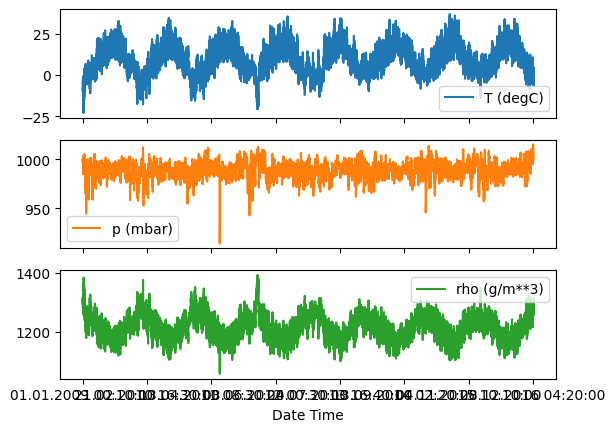

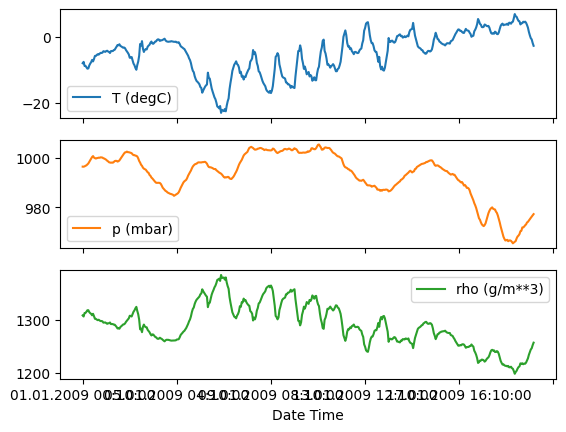

In [4]:
plot_cols = ['T (degC)', 'p (mbar)', 'rho (g/m**3)']
plot_features = df[plot_cols]
plot_features.index = df['Date Time']
_ = plot_features.plot(subplots=True)

plot_features = df[plot_cols][:480]
plot_features.index = df['Date Time'][:480]
_ = plot_features.plot(subplots=True)

## Preprocesado de los datos

Primero de nada, vamos a observar las estadísticas de cada dato. Para ello, la librería Pandas nos permite obtener información de una manera muy sencilla.

In [5]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
p (mbar),70092.0,989.212830,8.358709,914.10,984.20,989.58,994.72,1015.28
T (degC),70092.0,9.450272,8.423862,-23.01,3.36,9.42,15.47,37.13
Tpot (K),70092.0,283.492874,8.504928,250.60,277.43,283.47,289.53,311.06
Tdew (degC),70092.0,4.955267,6.730338,-25.01,0.23,5.22,10.06,23.11
rh (%),70092.0,76.005225,16.477654,14.20,65.21,79.30,89.40,100.00
VPmax (mbar),70092.0,13.576563,7.739742,0.95,7.78,11.82,17.60,63.26
VPact (mbar),70092.0,9.533275,4.183679,0.79,6.21,8.86,12.35,28.32
VPdef (mbar),70092.0,4.043228,4.898197,0.00,0.87,2.19,5.30,45.42
sh (g/kg),70092.0,6.022089,2.655839,0.50,3.92,5.59,7.80,18.13
H2OC (mmol/mol),70092.0,9.639723,4.234911,0.80,6.28,8.96,12.48,28.82


### Limpiar el dataset
En los datos podemos ver cosas extrañas. Por ejemplo, en la velocidad **wv** tenemos, como dato mínimo, valores de -9999m/s, que es una velocidad absurda. En este caso tenemos dos opciones:

1. Eliminar las filas con el error.
1. Poner un dato más fiable.

En nuestro caso, vamos a decidirnos por la última, sustituyendo cualquier valor menor que 0 por un 0.


In [6]:
# TODO: sustituye los datos negativos de las columnas wv (m/s) y max. wv (m/s) por 0's
wv = df['wv (m/s)']
wv_negativos = wv < 0
wv[wv_negativos] = 0

wv_max = df['max. wv (m/s)']
wv_max_negativos = wv_max < 0
wv_max[wv_max_negativos] = 0

Si la operación se ha completado satisfactoriamente, puedes volver a evaluar las estadísticas del dataset para comprobar que se han modificado los valores.

### Transformación de datos

Si observamos los datos vemos que tenemos ciertos componentes que necesitan ser preprocesados para que la representación sea más adecuada para la red neuronal.

#### Viento

El viento se compone de las 3 últimas variables. En especial la última, **wd (deg)**, que marca la dirección del viento. ¿Cuál es el problema que contiene esta variable? Tómate un tiempo para evaluar la problemática.

<font color='red'>TODO:</font> Escribe aquí el motivo por el que crees que la variable **wd (deg)** puede ser problemática en su forma actual. <font color='red'>PISTA:</font> Piensa en cómo se codifican los vientos que apuntan cerca del norte.



¿Ya te has dado cuenta del problema? ¡Es hora de arreglarlo! Sustituye el dato por una representación más útil.

<font color='red'>PISTA:</font> la solución implica dividir la variable en dos nuevos campos que se corresponden con funciones trigonométricas.

In [7]:
# Convertimos los grados a radianes
wd_rad = df.pop('wd (deg)')*np.pi / 180

# TODO: modifica wd (deg) para obtener una mejor representación
# Crea los nuevos componentes e insértalos en el dataframe.
df['Wx'] = df['wv (m/s)'] * np.cos(wd_rad)
df['Wy'] = df['wv (m/s)'] * np.sin(wd_rad)

# Hacemos lo mismo para el viento máximo
df['max. Wx'] = df['max. wv (m/s)'] * np.cos(wd_rad)
df['max. Wy'] = df['max. wv (m/s)'] * np.sin(wd_rad)

#### Fecha

La fecha es también algo muy importante en los datos, pero hay que tener en cuenta su periodicidad. En concreto, dos casos:

- Periodicidad en la hora del día.
- Periodicidad en la época del año.

Un método simple para convertirlo en una señal utilizable es usar el [seno](https://numpy.org/doc/stable/reference/generated/numpy.sin.html) y el [coseno](https://numpy.org/doc/stable/reference/generated/numpy.cos.html) para convertir la hora en señales claras de "Hora del día" y "Hora del año". Hay que operar de tal manera que:

1. $\cos(hora~0) = \cos(hora~24)$ y $\sin(hora~0) = \sin(hora~24)$ en la hora del día.
1. $\cos(1~enero) \approx \cos(31~diciembre)$ y $\sin(1~enero) \approx \sin(31~diciembre)$ en la hora anual.

<font color='red'>PISTA:</font> recuerda que:
- $\cos(0) = \cos(2\pi)$.
- $\sin(0) = \sin(2\pi)$.

In [8]:
# Vamos a quitar la columna de la fecha
date_time = pd.to_datetime(df.pop('Date Time'), format='%d.%m.%Y %H:%M:%S')

# Lo convertimos en segundos
timestamp_s = date_time.map(pd.Timestamp.timestamp)

# TODO: calcula el número de segundos de un día y de un año
day = 24 * 60 * 60
year = (365.2425) * day

# TODO: Extrae, para cada fecha, el seno y el coseno, y añádelos al dataframe
df['Dia sin'] = np.sin(timestamp_s * (2 * np.pi / day))
df['Dia cos'] = np.cos(timestamp_s * (2 * np.pi / day))
df['Anho sin'] = np.sin(timestamp_s * (2 * np.pi / year))
df['Anho cos'] = np.cos(timestamp_s * (2 * np.pi / year))

## Partición de datos

Usaremos una división **(70%, 20%, 10%)** para los conjuntos de entrenamiento, validación y prueba. Tenga en cuenta que los datos **no** se mezclan aleatoriamente antes de dividirlos. Esto es por dos razones:

1. Garantiza que aún sea posible dividir los datos en ventanas de muestras consecutivas.
1. Garantiza que los resultados de la validación / prueba sean más realistas y se evalúen en función de los datos recopilados después de que el modelo haya sido entrenado.

In [9]:
# TODO: parte los datos según el porcentaje estipulado
n_datos = len(df)

train_df = df[0:int(n_datos*0.7)]
val_df = df[int(n_datos*0.7):int(n_datos*0.9)]
test_df = df[int(n_datos*0.9):]

# Estandarización de los datos

Para que una red neuronal entrene correctamente suele ser necesario que todos los datos tengan una misma escala, o al menos una parecida. Sin embargo, anteriormente hemos visto como algunas variables tienen medias cercanas a 1000, mientras que otras rondan el 0. Por tanto, necesitamos igualarlas.

Existen múltiples maneras de escalar los datos, pero una de las más comunes es la estandarización:

$$ \tilde{x} = \dfrac{x - mean(x)}{std(x)} $$

Consiste en restar, **a cada columna**, su media, dividiendo el resultado por su desviación típica. Para realizarlo, podemos hacer uso de las funciones de Pandas [mean](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.mean.html) y [std](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.std.html).

Otra cosa a tener en cuenta es que **se usa la media y desviación del conjunto de entrenamiento** para normalizar todos los datos. Esto es así porque es el único conjunto de datos que conoceríamos a priori en un problema real.

In [10]:
# TODO = normaliza los dataframes
train_mean = train_df.mean()
train_std = train_df.std()

train_df = (train_df - train_mean) / train_std
val_df = (val_df - train_mean) / train_std
test_df = (test_df - train_mean) / train_std

Ahora podemos observar como los datos están más o menos en la misma escala.

/tmp/ipykernel_2767/2121202911.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ = ax.set_xticklabels(df.keys(), rotation=90)


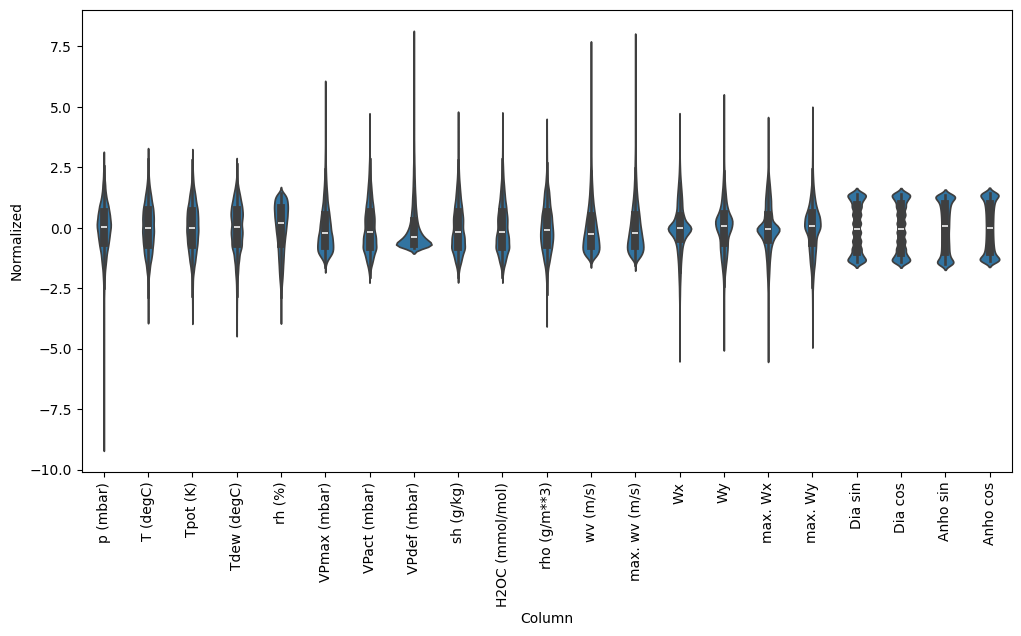

In [11]:
df_std = train_df.melt(var_name='Column', value_name='Normalized')
plt.figure(figsize=(12, 6))
ax = sns.violinplot(x='Column', y='Normalized', data=df_std)
_ = ax.set_xticklabels(df.keys(), rotation=90)

## Ventana de datos

Los modelos de esta práctica harán un conjunto de predicciones basadas en una ventana de muestras consecutivas de los datos. La agrupación de los datos se determinará mediante 3 parámetros:

1. **Anchura de la entrada (input_width):** Es el número de datos de diferentes tiempos que vamos a meter en el modelo.
1. **Anchura de la salida (label_width):** Es el número de datos de diferentes tiempos que vamos a tratar de predecir.
1. **Retardo de la salida (offset):** Es el tiempo a pasar entre el último dato de la entrada y el primero de la salida.

Aquí podemos ver una serie de distintos ejemplos:

`input_width = 5, label_width = 1, offset = 1`

<img src="https://github.com/eirasf/GCED-AA2/blob/main/es/lab9/im%C3%A1genes/ventana1.png?raw=1" alt="Ventana de ejemplo 1" width="400"/>


`input_width = 24, label_width = 4, offset = 0`

<img src="https://github.com/eirasf/GCED-AA2/blob/main/es/lab9/im%C3%A1genes/ventana2.png?raw=1" alt="Ventana de ejemplo 2" width="400"/>


El objetivo de esta parte es **crear una función que divida el dataset de entrada en todos los segmentos posibles de entrada/salida**, teniendo en cuenta los 3 parámetros mencionados anteriormente.

In [12]:
# TODO: completa la función sliding_window, sustituyendo las partes en que se indica None
def sliding_window(data, labels, input_width, label_width=1, offset=1):
    x = []
    y = []

    # El número total de ventanas válidas posibles es len(data) - input_width - offset - label_width + 1
    # Si offset es negativo, por ejemplo -input_width + 1, permite que el label comience solapado dentro del input
    total_steps = len(data) - input_width - (label_width + offset - 1)
    for i in range(total_steps):
        _x = data[i:i+input_width]
        start_y = i + input_width + offset
        _y = labels[start_y:start_y+label_width]
        x.append(_x)
        y.append(_y)

    x, y = np.array(x), np.array(y)

    if len(x.shape) == 2:
        x = x[:,:,np.newaxis]

    if len(y.shape) == 2:
        y = y[:,:,np.newaxis]

    return x, y

# Prueba el código
prueba_x, prueba_y = sliding_window(np.arange(5), np.arange(5), input_width=3, label_width=2, offset=-2)
print((prueba_x, prueba_y))
assert(prueba_x.shape == (3, 3, 1) and prueba_y.shape == (3, 2, 1))

(array([[[0],
        [1],
        [2]],

       [[1],
        [2],
        [3]],

       [[2],
        [3],
        [4]]]), array([[[1],
        [2]],

       [[2],
        [3]],

       [[3],
        [4]]]))


Una vez creada la función, se la pasamos a nuestros datos. Primero, definimos los parámetros de la función.

In [13]:
input_width = 24
label_width = 24
offset = -input_width + 1
target_labels = 'T (degC)' # Vamos a tratar de predecir la temperatura

# TODO: Llama a la función para dividir el dataset
x_train, y_train = sliding_window(train_df.values, train_df[target_labels].values, input_width, label_width, offset)
x_val, y_val = sliding_window(val_df.values, val_df[target_labels].values, input_width, label_width, offset)
x_test, y_test = sliding_window(test_df.values, test_df[target_labels].values, input_width, label_width, offset)

Vamos a comprobar el tamaño de los datos.

In [14]:
print('x_train shape :', x_train.shape)
print('y_train shape :', y_train.shape)

x_train shape : (49040, 24, 21)
y_train shape : (49040, 24, 1)


## Creando el modelo

Una vez obtenido un correcto preprocesado de los datos, vamos a crear el modelo. En `torch` tenemos implementado tanto las capas recurrentes [GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html) y [LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html). Además, también es posible crear cualquier capa recurrente que queramos utilizando el módulo [RNN](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html).

Nuestro primer modelo constará de dos partes:

1. Capa recurrente ([LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html))
1. Capa densa, para adecuar la salida al tamaño esperado.

El módulo LSTM nos devuelve una salida para cada entrada:

![](https://drive.google.com/uc?export=view&id=17SYlF1UqHdCTTxZangKABGEwd_Mse44p)

Esto es útil para:
  * Apilamiento de capas RNN.
  * Entrenamiento de un modelo en múltiples pasos de tiempo simultáneamente.

En nuestro caso, aprovechamos una secuencia larga para supervisar las predicciones del modelo en cada momento. Para ello, hemos elegido las etiquetas de manera que se solapen con las entradas, tal como se muestra en el diagrama. La salida de nuestro modelo debe ser tan ancha como el número de pasos temporales contenidos en nuestras etiquetas (en este caso 24).

In [15]:
# TODO: Completa el modelo con las partes necesarias
import torch
import torch.nn as nn

class LSTMModel(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=32, batch_first=True)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        out, _ = self.lstm(x)      # out: [batch, time, 32]
        out = self.fc(out)         # [batch, time, 1]
        return out

lstm_model = LSTMModel(input_size=x_train.shape[-1])

## Entrenando el modelo

Por último, sólo nos queda entrenar el modelo durante 20 iteraciones. Haz *early stopping* para que pare el entrenamiento si el resultado en validación no mejora pasadas una serie de iteraciones.

In [16]:
import torch.optim as optim
import torch.utils.data as data
import copy

MAX_EPOCHS = 20
batch_size = 32
loss_fn = nn.MSELoss()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
lstm_model = lstm_model.to(device)
optimizer = optim.Adam(lstm_model.parameters(), lr=0.001)
patience = 5

# TODO - Crea los DataLoaders necesarios y realiza el entrenamiento con early stopping
train_dataset = data.TensorDataset(torch.tensor(x_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
val_dataset = data.TensorDataset(torch.tensor(x_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32))
test_dataset = data.TensorDataset(torch.tensor(x_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.float32))

train_loader = data.DataLoader(train_dataset, shuffle=True, batch_size=batch_size)
val_loader = data.DataLoader(val_dataset, shuffle=False, batch_size=batch_size)
test_loader = data.DataLoader(test_dataset, shuffle=False, batch_size=batch_size)

best_loss = float('inf')
patience_counter = 0
best_model_weights = copy.deepcopy(lstm_model.state_dict())

for epoch in range(MAX_EPOCHS):
    lstm_model.train()
    train_loss = 0.0
    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        predictions = lstm_model(x_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * x_batch.size(0)
    train_loss /= len(train_loader.dataset)

    lstm_model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x_batch, y_batch in val_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            predictions = lstm_model(x_batch)
            loss = loss_fn(predictions, y_batch)
            val_loss += loss.item() * x_batch.size(0)
    val_loss /= len(val_loader.dataset)

    print(f"Epoch {epoch+1}/{MAX_EPOCHS} - Train loss: {train_loss:.4f}\n\tVal loss: {val_loss:.4f}")

    if val_loss < best_loss:
        best_loss = val_loss
        patience_counter = 0
        best_model_weights = copy.deepcopy(lstm_model.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("Early stopping triggered!")
            break

lstm_model.load_state_dict(best_model_weights)

Epoch 1/20 - Train loss: 0.0253
	Val loss: 0.0064
Epoch 2/20 - Train loss: 0.0064
	Val loss: 0.0058
Epoch 3/20 - Train loss: 0.0059
	Val loss: 0.0056
Epoch 4/20 - Train loss: 0.0057
	Val loss: 0.0056
Epoch 5/20 - Train loss: 0.0056
	Val loss: 0.0056
Epoch 6/20 - Train loss: 0.0055
	Val loss: 0.0055
Epoch 7/20 - Train loss: 0.0054
	Val loss: 0.0055
Epoch 8/20 - Train loss: 0.0053
	Val loss: 0.0055
Epoch 9/20 - Train loss: 0.0053
	Val loss: 0.0055
Epoch 10/20 - Train loss: 0.0052
	Val loss: 0.0055
Epoch 11/20 - Train loss: 0.0052
	Val loss: 0.0055
Epoch 12/20 - Train loss: 0.0051
	Val loss: 0.0056
Epoch 13/20 - Train loss: 0.0051
	Val loss: 0.0055
Epoch 14/20 - Train loss: 0.0051
	Val loss: 0.0055
Early stopping triggered!


<All keys matched successfully>

### Visualizando el resultado

Una vez entrenado el modelo, vamos a ver cómo hace la predicción en test, con respecto al resultado esperado.

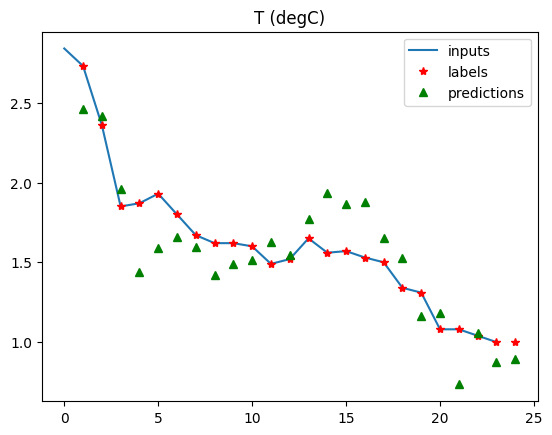

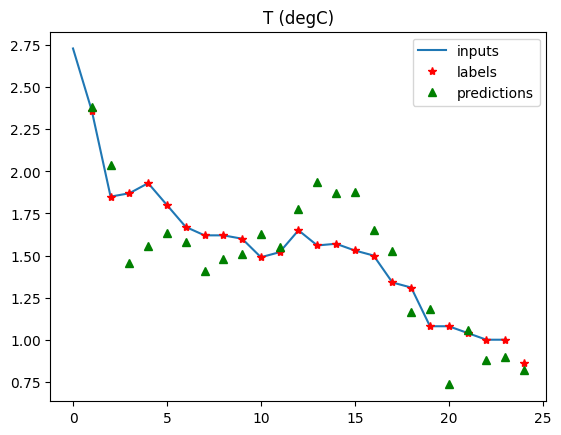

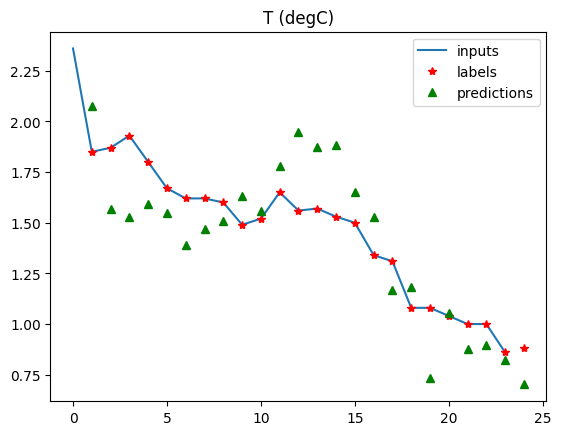

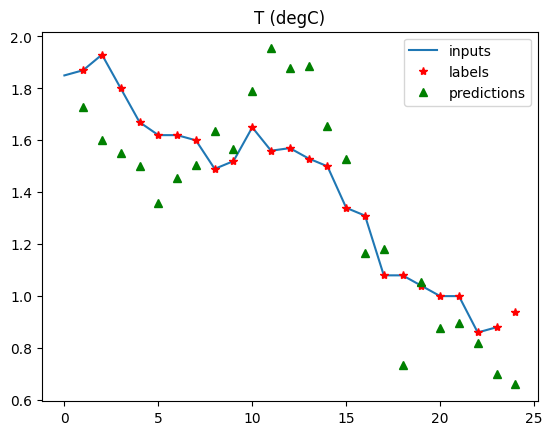

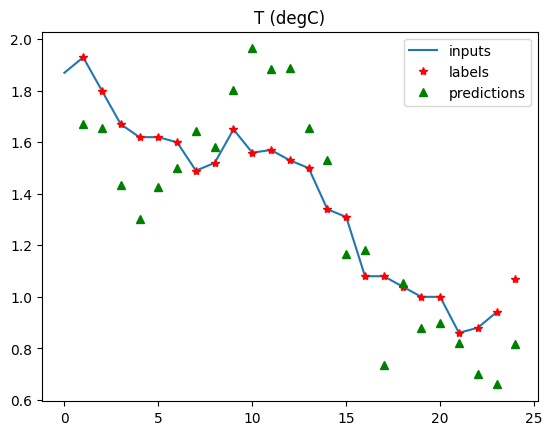

In [18]:
def plot_prediction(feed_data, expected_result, model_result, target_label, offset=1, index=0):
    f_data_x = np.arange(feed_data.shape[1])
    e_data_x = np.arange(expected_result.shape[1]) + offset
    plt.plot(f_data_x, feed_data[index])
    plt.plot(e_data_x, expected_result[index], '*r')
    plt.plot(e_data_x, model_result[index], '^g')
    plt.legend(['inputs', 'labels', 'predictions'])
    plt.title(target_label)
    plt.show()

# TODO: Coge un lote de test y haz la predicción con el modelo
test_batch = next(iter(test_loader))
x_test_b, y_test_b = test_batch
x_test_b = x_test_b.to(device)
y_test_b = y_test_b.to(device)

lstm_model.eval()
with torch.no_grad():
    model_result = lstm_model(x_test_b).detach().cpu().numpy()

target_index = test_df.columns.get_loc(target_labels)
temp_mean = train_mean[target_labels]
temp_std = train_std[target_labels]

# Desestandarizamos para el ploteo correcto en grados reales
feed_data_unnorm = x_test_b.detach().cpu().numpy()[:, :, target_index] * temp_std + temp_mean
expected_unnorm = y_test_b.detach().cpu().numpy()[:, :, 0] * temp_std + temp_mean
predictions_unnorm = model_result[:, :, 0] * temp_std + temp_mean

for i in range(5):
  # TODO: llama a la función plot_prediction con los parámetros correctos (reemplaza los None)
  plot_prediction(feed_data_unnorm,
                  expected_unnorm,
                  predictions_unnorm,
                  target_labels,
                  label_width + offset,
                  index=i)

La predicción es bastante cercana...pero algo falla. Fíjate en el eje de las Y; ¡eso no las temperaturas! **¡Las temperaturas están mostrando el resultado estandarizado!** Revierte la normalización para un correcto visualizado.

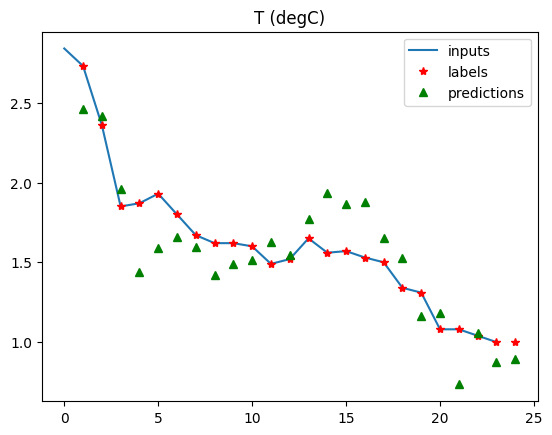

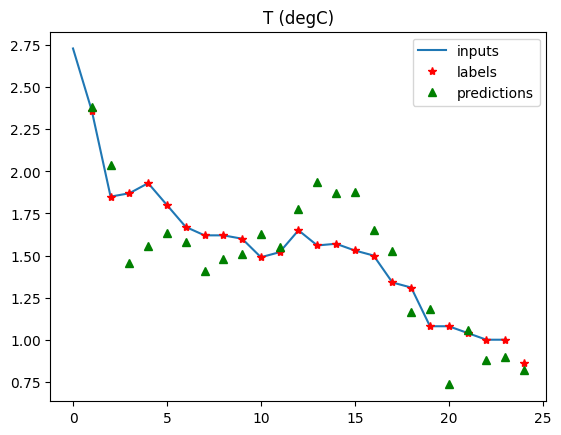

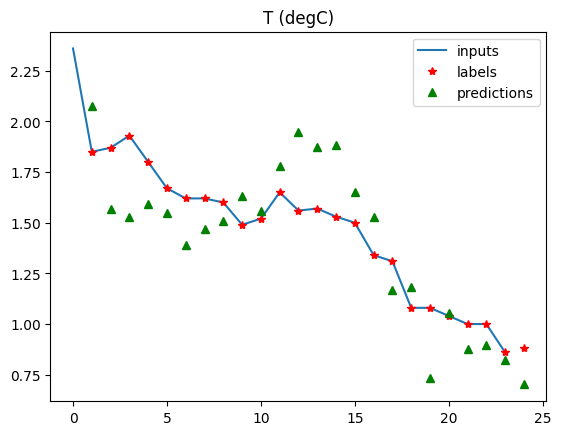

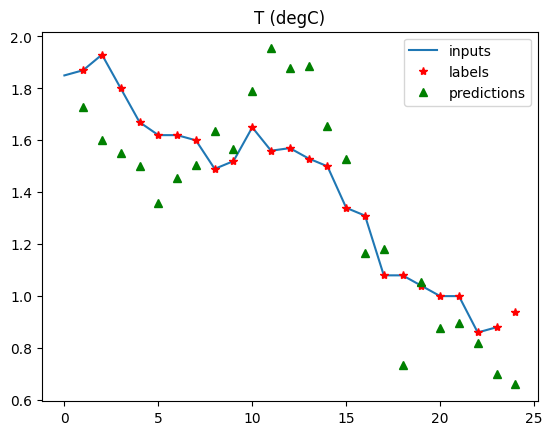

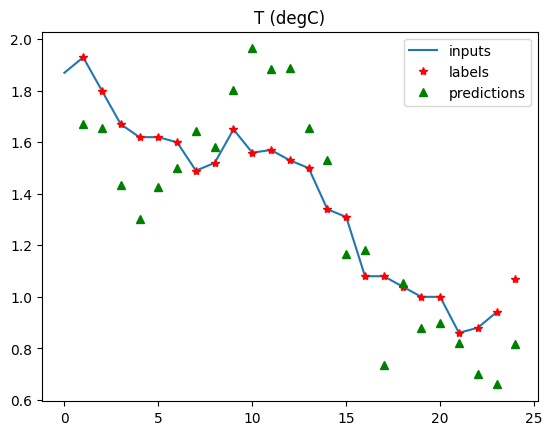

In [19]:
# TODO: llama a la función plot_prediction con los valores sin estandarizar
# Obtenemos la media y std de la temperatura para desestandarizar
temp_mean = train_mean[target_labels]
temp_std = train_std[target_labels]

lstm_model.eval()
with torch.no_grad():
    test_batch = next(iter(test_loader))
    x_test_b, y_test_b = test_batch
    x_test_b = x_test_b.to(device)
    model_result = lstm_model(x_test_b).detach().cpu().numpy()

target_index = test_df.columns.get_loc(target_labels)
x_test_b_np = x_test_b.detach().cpu().numpy()
y_test_b_np = y_test_b.detach().cpu().numpy()

# Deshacemos la estandarización multiplicando por la desviación típica y sumando la media
feed_data_unnorm = x_test_b_np[:, :, target_index] * temp_std + temp_mean
expected_unnorm = y_test_b_np[:, :, 0] * temp_std + temp_mean
predictions_unnorm = model_result[:, :, 0] * temp_std + temp_mean

for i in range(5):
    plot_prediction(feed_data_unnorm,
                    expected_unnorm,
                    predictions_unnorm,
                    target_labels,
                    label_width + offset,
                    index=i)

¡Enhorabuena! Has creado tu primera red recursiva. Ahora vamos a hacerlo un poco más complejo.

# Predicción de múltiples pasos a futuro

El modelo que vimos anteriormente utiliza la salida de cada entrada del LSTM para predecir el tiempo siguiente, es decir, solo predice un valor que no tuviese como entrada (los otros 23 se usan solo para supervisar al modelo).

**¿Qué pasaría entonces si uso el mismo modelo para predecir la temperatura en las 24h siguientes?** Como nuestro modelo espera tener siempre datos de la hora anterior a la predicha, tendríamos que ir utilizando las predicciones anteriores como entradas para hacer cada predicción siguiente, lo que se conoce como un modelo autoregresivo.

$$
pred_{24} = model(x_0,...,x_{23})\\
pred_{25} = model(x_1,...,x_{23},pred_{24})\\
...\\
pred_{47} = model(x_{23},pred_{24},...,pred_{46})
$$

Esto requeriría hacer 24 llamadas al modelo. Para evitar ese gasto computacional, cambiaremos nuestro modelo para que devuelva las predicciones de las 24h siguientes. Esto también mejorará las predicciones del modelo, porque durante el entrenamiento cada predicción informará a todas las celdas del LSTM, ya que todas están por detrás de ella. Esto hará que las predicciones del modelo a largo plazo sean mejores que utilizando el método autoregresivo.

En primer lugar, definamos las ventanas de manera que las etiquetas se correspondan con las 24h siguientes a las suministradas como entrada.

In [20]:
input_width = 24
label_width = 24
offset = 0
target_labels = 'T (degC)' # Vamos a tratar de predecir la temperatura

# TODO: Llama a la función para hacer el ventaneo
x_train, y_train = sliding_window(train_df.values, train_df[target_labels].values, input_width, label_width, offset)
x_val, y_val = sliding_window(val_df.values, val_df[target_labels].values, input_width, label_width, offset)
x_test, y_test = sliding_window(test_df.values, test_df[target_labels].values, input_width, label_width, offset)

train_dataset = data.TensorDataset(torch.tensor(x_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
val_dataset = data.TensorDataset(torch.tensor(x_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32))
test_dataset = data.TensorDataset(torch.tensor(x_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.float32))

train_loader = data.DataLoader(train_dataset, shuffle=True, batch_size=batch_size)
val_loader = data.DataLoader(val_dataset, shuffle=False, batch_size=batch_size)
test_loader = data.DataLoader(test_dataset, shuffle=False, batch_size=batch_size)

## Creando el modelo

En este modelo vamos a necesitar acumular la información de las 24h de entrada para empezar a predecir los resultados a la salida. El esquema a seguir es el siguiente:

![](https://drive.google.com/uc?export=view&id=1R1tGHuXo2yueWlNyP1tWfgQLM6YP1xPw)

Para dar mayor capacidad al modelo, vamos a concatenar dos capas LSTM. La segunda capa tomará como entrada la salida de la primera, que tiene tantas componentes como haya en la entrada (ver diagrama del apartado *Creando el modelo*). La red lineal de predicción solo tomará como entrada la última salida de la segunda capa LSTM, como se muestra en el diagrama de esta celda.

In [21]:
import torch
import torch.nn as nn

class StackedLSTMModel(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.lstm1 = nn.LSTM(input_size=input_size, hidden_size=32, batch_first=True)
        self.lstm2 = nn.LSTM(input_size=32, hidden_size=32, batch_first=True)
        self.fc = nn.Linear(32, 24) # Necesitamos predecir 24 valores de salida correspondientes a las 24 horas
        self.reshape = lambda x: x.unsqueeze(-1)  # reorganizamos la salida para que tenga shape (label_width, n_output_features)

    def forward(self, x):
        # TODO - Completa la función
        # Asegúrate de que la parte densa de la red toma solo la última salida del LSTM
        out, _ = self.lstm1(x)
        out, _ = self.lstm2(out)
        out = out[:, -1, :] # Tomamos la última componente del eje temporal
        out = self.fc(out) # out: [batch, 24]
        out = self.reshape(out) # out: [batch, 24, 1]
        return out

lstm_model = StackedLSTMModel(input_size=x_train.shape[-1])

## Entrenando el modelo

Por último, sólo nos queda entrenar el modelo durante 20 iteraciones.

In [22]:
# TODO - Haz el entrenamiento del modelo
import copy
lstm_model = lstm_model.to(device)
optimizer = optim.Adam(lstm_model.parameters(), lr=0.001)
best_loss = float('inf')
patience_counter = 0
best_model_weights = copy.deepcopy(lstm_model.state_dict())

for epoch in range(MAX_EPOCHS):
    lstm_model.train()
    train_loss = 0.0
    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        predictions = lstm_model(x_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * x_batch.size(0)
    train_loss /= len(train_loader.dataset)

    lstm_model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x_batch, y_batch in val_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            predictions = lstm_model(x_batch)
            loss = loss_fn(predictions, y_batch)
            val_loss += loss.item() * x_batch.size(0)
    val_loss /= len(val_loader.dataset)

    print(f"Epoch {epoch+1}/{MAX_EPOCHS} - Train loss: {train_loss:.4f}\n\tVal loss: {val_loss:.4f}")

    if val_loss < best_loss:
        best_loss = val_loss
        patience_counter = 0
        best_model_weights = copy.deepcopy(lstm_model.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("Early stopping triggered!")
            break

lstm_model.load_state_dict(best_model_weights)

Epoch 1/20 - Train loss: 0.1158
	Val loss: 0.0804
Epoch 2/20 - Train loss: 0.0714
	Val loss: 0.0789
Epoch 3/20 - Train loss: 0.0668
	Val loss: 0.0737
Epoch 4/20 - Train loss: 0.0637
	Val loss: 0.0766
Epoch 5/20 - Train loss: 0.0614
	Val loss: 0.0767
Epoch 6/20 - Train loss: 0.0592
	Val loss: 0.0741
Epoch 7/20 - Train loss: 0.0570
	Val loss: 0.0772
Epoch 8/20 - Train loss: 0.0546
	Val loss: 0.0780
Early stopping triggered!


<All keys matched successfully>

### Visualizando el resultado

Una vez entrenado el modelo, vamos a ver cómo hace la predicción en test, con respecto al resultado esperado.

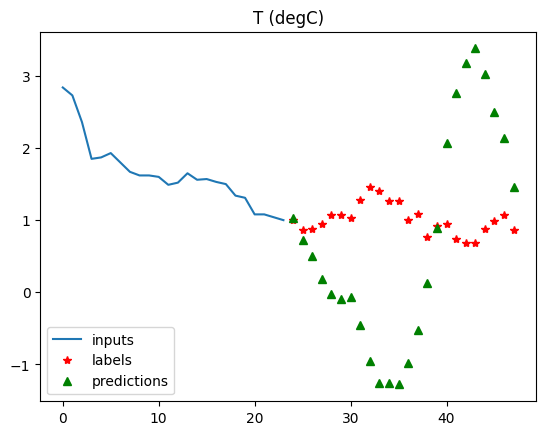

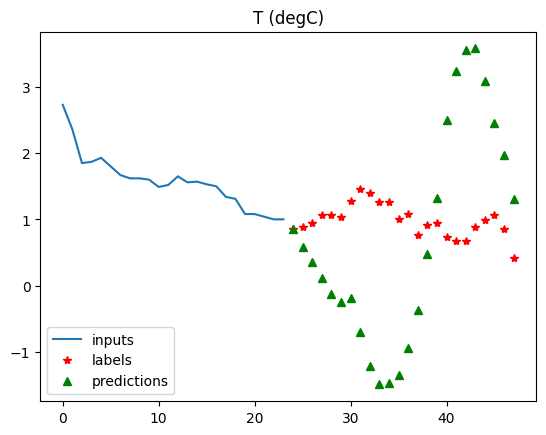

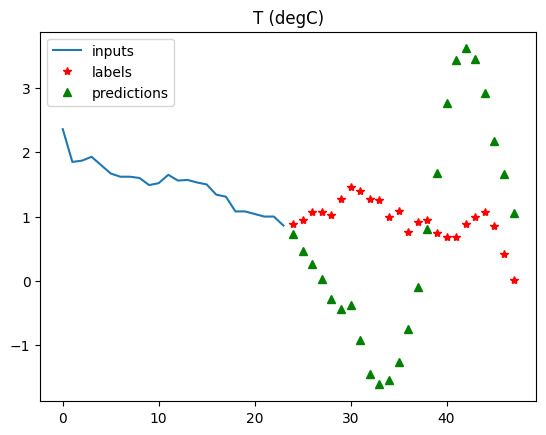

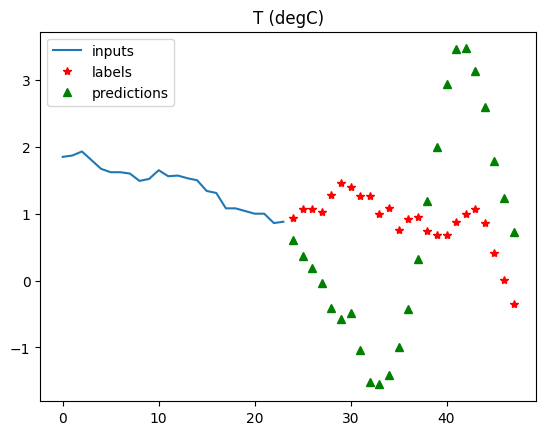

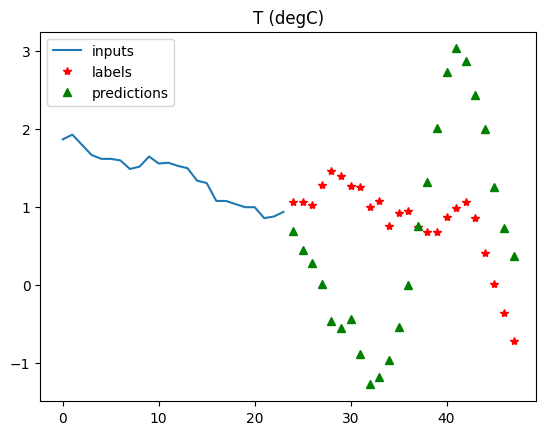

In [23]:
# TODO: Coge un lote de test y haz la predicción con el modelo
lstm_model.eval()
with torch.no_grad():
    test_batch = next(iter(test_loader))
    x_test_b, y_test_b = test_batch
    x_test_b = x_test_b.to(device)
    model_result = lstm_model(x_test_b).detach().cpu().numpy()

target_index = test_df.columns.get_loc(target_labels)
temp_mean = train_mean[target_labels]
temp_std = train_std[target_labels]

# Desestandarizamos para el ploteo correcto
feed_data_unnorm = x_test_b.detach().cpu().numpy()[:, :, target_index] * temp_std + temp_mean
expected_unnorm = y_test_b.numpy()[:, :, 0] * temp_std + temp_mean
predictions_unnorm = model_result[:, :, 0] * temp_std + temp_mean

for i in range(5):
    plot_prediction(feed_data_unnorm,
                    expected_unnorm,
                    predictions_unnorm,
                    target_labels,
                    offset=input_width,
                    index=i)

Como puedes ver y es de esperar, es muchísimo más difícil hacer predicciones con mucha antelación.

# ¡ENHORABUENA! Has completado la práctica de Redes recurrentes.

# ¿Deseas saber más?

Puedes profundizar en las redes que utilizan como datos de entradas las mismas predicciones de la red en tiempos anteriores. Son las llamadas [redes auto-regresivas](https://eigenfoo.xyz/deep-autoregressive-models/).

# Trabajo extra

Como trabajo extra, se propone realizar una idea parecida, pero con dificultad añadida.

- Se utilizará una capa [GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html) en lugar de la LSTM.
- Se propone predecir todas las variables del dataset al mismo tiempo, en lugar de sólo la temperatura.

In [ ]:
# TODO: escribe el código para el trabajo extra sin ayuda. Usa todos los bloques de código que quieras.


### 1. Ventaneo para Predecir Todas las Variables al Mismo Tiempo

En lugar de seleccionar una única columna objetivo (`T (degC)`), pasaremos todo el conjunto de características (el DataFrame al completo) como entrada y salida de nuestra función de ventaneo.

In [24]:
input_width = 24
label_width = 24
offset = 0

# Pasamos todos los valores del DataFrame para predecir todas las variables simultáneamente
x_train_multi, y_train_multi = sliding_window(train_df.values, train_df.values, input_width, label_width, offset)
x_val_multi, y_val_multi = sliding_window(val_df.values, val_df.values, input_width, label_width, offset)
x_test_multi, y_test_multi = sliding_window(test_df.values, test_df.values, input_width, label_width, offset)

print('x_train_multi shape:', x_train_multi.shape)
print('y_train_multi shape:', y_train_multi.shape)

x_train_multi shape: (49017, 24, 21)
y_train_multi shape: (49017, 24, 21)


### 2. Creación del Modelo de Red Neuronal GRU

Definimos una arquitectura con dos capas GRU apiladas de 32 unidades ocultas, seguidas de una capa lineal proyectando a la dimensión final de (24 pasos de tiempo $\times$ 21 variables).

In [25]:
class StackedGRUModel(nn.Module):
    def __init__(self, input_size, num_features, label_width=24):
        super().__init__()
        self.num_features = num_features
        self.label_width = label_width

        self.gru1 = nn.GRU(input_size=input_size, hidden_size=32, batch_first=True)
        self.gru2 = nn.GRU(input_size=32, hidden_size=32, batch_first=True)
        self.fc = nn.Linear(32, label_width * num_features)

    def forward(self, x):
        out, _ = self.gru1(x)
        out, _ = self.gru2(out)
        out = out[:, -1, :]  # Tomamos la salida del último paso temporal
        out = self.fc(out)   # Proyección lineal
        out = out.view(-1, self.label_width, self.num_features)  # Reshape a [batch, label_width, num_features]
        return out

num_features = x_train_multi.shape[-1]
gru_model = StackedGRUModel(input_size=num_features, num_features=num_features)

### 3. Entrenamiento con Early Stopping

In [26]:
train_dataset_m = data.TensorDataset(torch.tensor(x_train_multi, dtype=torch.float32), torch.tensor(y_train_multi, dtype=torch.float32))
val_dataset_m = data.TensorDataset(torch.tensor(x_val_multi, dtype=torch.float32), torch.tensor(y_val_multi, dtype=torch.float32))
test_dataset_m = data.TensorDataset(torch.tensor(x_test_multi, dtype=torch.float32), torch.tensor(y_test_multi, dtype=torch.float32))

train_loader_m = data.DataLoader(train_dataset_m, shuffle=True, batch_size=batch_size)
val_loader_m = data.DataLoader(val_dataset_m, shuffle=False, batch_size=batch_size)
test_loader_m = data.DataLoader(test_dataset_m, shuffle=False, batch_size=batch_size)

gru_model = gru_model.to(device)
optimizer = optim.Adam(gru_model.parameters(), lr=0.001)
best_loss_m = float('inf')
patience_counter = 0
best_model_weights_m = copy.deepcopy(gru_model.state_dict())

for epoch in range(MAX_EPOCHS):
    gru_model.train()
    train_loss = 0.0
    for x_batch, y_batch in train_loader_m:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        predictions = gru_model(x_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * x_batch.size(0)
    train_loss /= len(train_loader_m.dataset)

    gru_model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x_batch, y_batch in val_loader_m:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            predictions = gru_model(x_batch)
            loss = loss_fn(predictions, y_batch)
            val_loss += loss.item() * x_batch.size(0)
    val_loss /= len(val_loader_m.dataset)

    print(f"Epoch {epoch+1}/{MAX_EPOCHS} - Train loss: {train_loss:.4f}\n\tVal loss: {val_loss:.4f}")

    if val_loss < best_loss_m:
        best_loss_m = val_loss
        patience_counter = 0
        best_model_weights_m = copy.deepcopy(gru_model.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("Early stopping triggered!")
            break

gru_model.load_state_dict(best_model_weights_m)

Epoch 1/20 - Train loss: 0.3348
	Val loss: 0.2851
Epoch 2/20 - Train loss: 0.2635
	Val loss: 0.2736
Epoch 3/20 - Train loss: 0.2523
	Val loss: 0.2691
Epoch 4/20 - Train loss: 0.2463
	Val loss: 0.2653
Epoch 5/20 - Train loss: 0.2422
	Val loss: 0.2669
Epoch 6/20 - Train loss: 0.2392
	Val loss: 0.2649
Epoch 7/20 - Train loss: 0.2365
	Val loss: 0.2643
Epoch 8/20 - Train loss: 0.2339
	Val loss: 0.2655
Epoch 9/20 - Train loss: 0.2318
	Val loss: 0.2669
Epoch 10/20 - Train loss: 0.2296
	Val loss: 0.2719
Epoch 11/20 - Train loss: 0.2277
	Val loss: 0.2703
Epoch 12/20 - Train loss: 0.2257
	Val loss: 0.2700
Early stopping triggered!


<All keys matched successfully>

### 4. Evaluación y Desestandarización de resultados

Visualizaremos las predicciones para dos variables clave distintas para probar la efectividad de la estimación simultánea: la temperatura (`T (degC)`) y la presión (`p (mbar)`).

--- Predicción Multi-variable para T (degC) ---


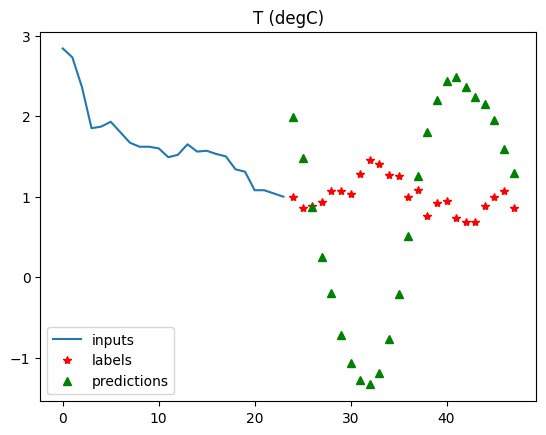

--- Predicción Multi-variable para p (mbar) ---


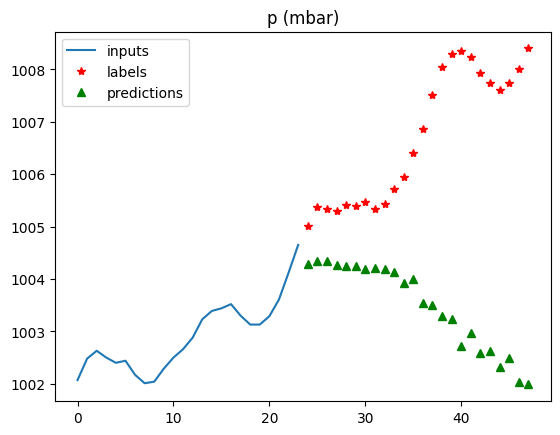

In [27]:
gru_model.eval()
with torch.no_grad():
    test_batch = next(iter(test_loader_m))
    x_test_b, y_test_b = test_batch
    x_test_b = x_test_b.to(device)
    model_result = gru_model(x_test_b).detach().cpu().numpy()

x_test_b_np = x_test_b.detach().cpu().numpy()
y_test_b_np = y_test_b.numpy()

def plot_multivariate_prediction(feature_name):
    feature_index = df.columns.get_loc(feature_name)
    f_mean = train_mean[feature_name]
    f_std = train_std[feature_name]

    # Desestandarizamos
    feed_data_unnorm = x_test_b_np[:, :, feature_index] * f_std + f_mean
    expected_unnorm = y_test_b_np[:, :, feature_index] * f_std + f_mean
    predictions_unnorm = model_result[:, :, feature_index] * f_std + f_mean

    print(f"--- Predicción Multi-variable para {feature_name} ---")
    plot_prediction(feed_data_unnorm, expected_unnorm, predictions_unnorm, feature_name, offset=input_width, index=0)

# Graficamos los resultados para Temperatura y Presión
plot_multivariate_prediction('T (degC)')
plot_multivariate_prediction('p (mbar)')